агент → трейсы в Langfuse → золотой набор → прогоны → оценка

Откройте ноутбук из корня проекта в PyCharm. Файлы данных: `data/raw/train.csv` и `data/raw/macro.csv`. Для запуска нужны `OPENROUTER_API_KEY`, `LANGFUSE_PUBLIC_KEY`, `LANGFUSE_SECRET_KEY` и `LANGFUSE_BASE_URL` в окружении или в файле `.env` в корне проекта. Пакеты ядра: duckdb, pandas, tabulate, matplotlib, openai, langfuse (4.x), python-dotenv.


In [15]:
import json, os, re, subprocess, sys, textwrap, time
import duckdb, pandas as pd

from pathlib import Path
from dotenv import dotenv_values, load_dotenv

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "standalone.ipynb").is_file():
    PROJECT_DIR = Path(r"C:\Users\demch\PycharmProjects\JupyterProject")
RAW_DIR = PROJECT_DIR / "data" / "raw"
load_dotenv(PROJECT_DIR / ".env")

from langfuse import Langfuse, observe, propagate_attributes
from langfuse.openai import OpenAI                            

AGENT_MODEL = "mistralai/ministral-8b-2512"                   # слабая модель под тестом: 8B, умеет function calling, 256k контекст
JUDGE_MODEL = "anthropic/claude-sonnet-5"                      # средняя модель судит
DB, MAX_STEPS, ROW_LIMIT, PY_TIMEOUT = RAW_DIR.parent / "sber.duckdb", 12, 50, 30
RUN_ID = time.strftime("run-%Y%m%d-%H%M%S")                   # session_id в Langfuse

langfuse = Langfuse()                                          
# При повторном выполнении ячейки берём актуальный ключ проекта, даже если ядро хранит прежний.
openrouter_key = dotenv_values(PROJECT_DIR / ".env").get("OPENROUTER_API_KEY") or os.environ["OPENROUTER_API_KEY"]
client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=openrouter_key, max_retries=3)
print("langfuse:", langfuse.auth_check(), "| run:", RUN_ID)

langfuse: True | run: run-20261110-010801


## 1. Простой агент

Данные: сделки с квартирами в Москве 2011–2015 (Kaggle «Sberbank Russian Housing Market») в DuckDB, три таблицы:
`deals` (сделки), `raion` (атрибуты района), `macro` (дневные макропоказатели). 
Данные грязные

In [16]:
train_csv = RAW_DIR / "train.csv"
macro_csv = RAW_DIR / "macro.csv"
for path in (train_csv, macro_csv):
    if not path.is_file():
        raise FileNotFoundError(path)

if not DB.exists():
    import tempfile
    with tempfile.TemporaryDirectory(dir=DB.parent) as tmp:
        stage = Path(tmp) / DB.name
        with duckdb.connect(str(stage)) as b:
            b.execute("""
                create table deals as select id, timestamp::date as date, price_doc as price, full_sq, life_sq, floor, max_floor,
                num_room, kitch_sq, build_year, state, material, product_type, sub_area, kremlin_km, metro_min_walk, metro_km_avto, ecology
                from read_csv_auto(?, nullstr='NA')
            """, [str(train_csv)])
            b.execute("""
                create table raion as select distinct sub_area, area_m, raion_popul, green_zone_part, indust_part,
                school_education_centers_top_20_raion as top20_schools, university_top_20_raion as top20_unis,
                shopping_centers_raion, thermal_power_plant_raion, detention_facility_raion, nuclear_reactor_raion
                from read_csv_auto(?, nullstr='NA')
            """, [str(train_csv)])
            b.execute("""
                create table macro as select timestamp::date as date, oil_urals, usdrub, eurrub, cpi, ppi, mortgage_rate,
                mortgage_value, salary, unemployment, rent_price_2room_eco, rent_price_1room_eco
                from read_csv_auto(?, nullstr='NA')
            """, [str(macro_csv)])
        stage.replace(DB)

con = duckdb.connect(str(DB), read_only=True)
for table in ["deals", "raion", "macro"]:
    print(table, con.sql(f"select count(*) from {table}").fetchone()[0], "rows")
con.sql("select * from deals").df().tail()


deals 30471 rows
raion 146 rows
macro 2484 rows


,id,date,price,full_sq,life_sq,floor,max_floor,num_room,kitch_sq,build_year,state,material,product_type,sub_area,kremlin_km,metro_min_walk,metro_km_avto,ecology
30466,30469,2015-06-30,7400000,44,27,7,9,2,6,1975,3,1,Investment,Otradnoe,12.599292,8.158093,0.659002,good
30467,30470,2015-06-30,25000000,86,59,3,9,4,10,1935,3,2,Investment,Tverskoe,3.269284,9.374609,0.781217,poor
30468,30471,2015-06-30,6970959,45,<NA>,10,20,1,1,<NA>,1,1,OwnerOccupier,Poselenie Vnukovskoe,21.905792,20.666800,1.722233,no data
30469,30472,2015-06-30,13500000,64,32,5,15,2,11,2003,2,1,Investment,Obruchevskoe,13.622569,24.567748,2.047312,satisfactory
30470,30473,2015-06-30,5600000,43,28,1,9,2,6,1968,2,1,Investment,Novogireevo,11.812614,5.455795,0.454650,poor


In [17]:
con.sql("select * from raion limit 5").df().tail()

,sub_area,area_m,raion_popul,green_zone_part,indust_part,top20_schools,top20_unis,shopping_centers_raion,thermal_power_plant_raion,detention_facility_raion,nuclear_reactor_raion
0,Juzhnoe Butovo,2.615514e+07,178264,0.137846,0.041116,1,0,4,False,False,False
1,Novokosino,3.707575e+06,103746,0.030566,0.041365,0,0,4,False,False,False
2,Chertanovo Central'noe,6.879020e+06,112221,0.061477,0.282798,0,0,6,False,False,False
3,Kotlovka,3.998216e+06,64317,0.258712,0.014423,0,0,3,False,False,False
4,Orehovo-Borisovo Severnoe,7.462270e+06,129207,0.387100,0.007720,0,0,4,False,False,False


In [18]:
con.sql("select * from macro limit 500").df().tail()

,date,oil_urals,usdrub,eurrub,cpi,ppi,mortgage_rate,mortgage_value,salary,unemployment,rent_price_2room_eco,rent_price_1room_eco
495,2011-05-11,111.14,27.7981,39.5247,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
496,2011-05-12,111.14,27.9392,39.8623,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
497,2011-05-13,111.14,28.1475,39.5707,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
498,2011-05-14,111.14,28.1475,39.5707,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94
499,2011-05-15,111.14,28.1475,39.5707,351.5,433.9,12.12,152437,44898.7,0.014,35.89,27.94


Инструменты аналитика: исполнение одного SQL-запроса в DuckDB и формирование ответа из результата. Для задач о ценовых заглушках используются профиль частот и сравнение двух правил исключения.

In [19]:
def parse_sql_step(reply):
    """Parse the action envelope and discard example output after the statement."""
    fence = chr(96) * 3
    text = reply.strip().replace(chr(0), '')
    if text.startswith(fence):
        text = text.partition('\n')[2].lstrip()
    action = re.match(r'^\s*(CHECK|RESULT)\s*:?\s*\n', text, re.I)
    kind = action.group(1).upper() if action else 'CHECK'
    sql = text[action.end():].strip() if action else text
    if sql.startswith(fence):
        sql = sql.partition('\n')[2]
    sql = re.split(r'(?m)^\s*' + fence + r'\s*$', sql, maxsplit=1)[0]
    # A model sometimes draws a Markdown table below the SQL. It is never evidence.
    sql = re.sub(r'(?ms)(;)[ \t]*\n\s*\|[^\n]*\|[ \t]*\n\s*\|[ |:\-]+\|.*\Z', r'\1', sql)
    return kind, sql.strip()


@observe(as_type='tool', name='run_sql')
def course_sql(query, *, as_records=False):
    try:
        statements = duckdb.extract_statements(query)
        if len(statements) != 1 or str(statements[0].type).split('.')[-1] != 'SELECT':
            raise ValueError('Нужен один SELECT или WITH ... SELECT')
        result = con.sql(query).limit(ROW_LIMIT)
        if as_records:
            return [dict(zip(result.columns, row)) for row in result.fetchall()]
        frame = result.df()
        if frame.empty:
            return 'EMPTY: запрос вернул 0 строк'
        return frame.to_markdown(index=False, floatfmt='.10g')
    except Exception as exc:
        return f'ERROR: {exc}'


@observe(as_type='tool', name='final_answer')
def course_final(text, result_table, *, result_rows=None):
    if not text and result_rows and len(result_rows) == 1 and 'pearson_r' in result_rows[0]:
        row = result_rows[0]
        if all(row.get(key) for key in ('x_label', 'y_label', 'sample_label')) and 'n_obs' in row:
            r = row['pearson_r']
            sample = f"Выборка: {row['sample_label']}. Число пар наблюдений: {row['n_obs']}."
            metrics = f"X — {row['x_label']}; Y — {row['y_label']}."
            if pd.isna(r):
                return f"{sample} {metrics} Коэффициент Пирсона не определён."
            if r < 0:
                direction = "Связь отрицательная: большим значениям Y в выборке обычно соответствуют меньшие значения X."
            elif r > 0:
                direction = "Связь положительная: большим значениям Y в выборке обычно соответствуют большие значения X."
            else:
                direction = "Коэффициент равен нулю: линейной связи в этой выборке не наблюдается."
            return f"{sample} {metrics} Коэффициент Пирсона r = {r:.5f}. {direction}"

    # Подпись описывает выборку, а число берём из типизированной строки DuckDB.
    if not text and result_rows and len(result_rows) == 1 and len(result_rows[0]) == 1:
        label, value = next(iter(result_rows[0].items()))
        label = ' '.join(label.replace('_', ' ').split())
        if label.lower().startswith(('число ', 'количество ')) and type(value) is int and value >= 0:
            number = format(value, ',d').replace(',', ' ')
            return f"{label[:1].upper()}{label[1:]} — {number}."

    return text.strip() + ('\n\nРезультат SQL\n' + result_table if result_table else '')


def profile_query(source):
    return f'''WITH source_rows AS ({source}),
    base AS (SELECT price AS val, product_type AS segment FROM source_rows
             WHERE price IS NOT NULL AND full_sq > 0),
    freq AS (SELECT val, count(*) AS n FROM base GROUP BY val),
    nb AS (SELECT *,lag(val) OVER w AS left_val,lag(n) OVER w AS left_n,lead(val) OVER w AS right_val,lead(n) OVER w AS right_n FROM freq WINDOW w AS (ORDER BY val)),
    topvals AS (SELECT * FROM nb ORDER BY n DESC,val LIMIT 16),
    segs AS (SELECT val,segment,count(*) AS segment_n FROM base GROUP BY val,segment)
    SELECT t.*,s.segment,s.segment_n FROM topvals t JOIN segs s USING(val) ORDER BY t.n DESC,t.val,s.segment_n DESC LIMIT 50'''

def local_price_scores():
    # Сначала самая узкая группа, затем два запасных уровня. Нулевой MAD не задаёт шкалу.
    levels = [('district', 'product_type', 'sale_year'), ('district', 'product_type'),
              ('product_type', 'sale_year')]
    windows, scores = [], []
    for i, keys in enumerate(levels):
        window = f"OVER (PARTITION BY {', '.join(keys)})"
        windows.extend([f"count(log_metric) {window} AS size_{i}",
                        f"median(log_metric) {window} AS center_{i}",
                        f"mad(log_metric) {window} AS spread_{i}"])
        known = ' AND '.join(f'{key} IS NOT NULL' for key in keys)
        scores.append(f"CASE WHEN {known} AND size_{i} >= 30 AND spread_{i} > 1e-10 "
                      f"THEN (log_metric - center_{i}) / (1.4826 * spread_{i}) END")
    return (f"peer_stats AS (SELECT *, {', '.join(windows)} FROM base), "
            f"scored AS (SELECT *, coalesce({', '.join(scores)}) AS local_z FROM peer_stats)")


def describe_price_scenarios(rows, question):
    if not rows:
        return "Нет сделок с положительными ценой и площадью. Медиана не определена."
    scenarios = {row['scenario']: row for row in rows}
    peaks = scenarios['exact_peaks']
    local = scenarios['local_mad']
    n = peaks['n_all']

    def result(row):
        kept = row['metric_kept']
        median = f"{kept:,.2f} ₽/м²" if kept is not None else "не определена"
        return (f"Кандидаты: {row['n_excluded']} из {n} ({row['candidate_pct']:.2f}%). "
                f"Медиана после исключения: {median}.")

    lines = [f"Исходная выборка: {n} сделок с положительными ценой и площадью. "
             f"Медиана со всеми сделками: {peaks['metric_all']:,.2f} ₽/м²."]
    if peaks['peak_counts']:
        counts = ", ".join(f"{p['price']:,} ₽ — {p['frequency']} сделок" for p in peaks['peak_counts'])
        evidence = (f"{counts}. Частота наименьшего пика / следующая частота: "
                    f"{peaks['last_peak_n']} / {peaks['next_n']} = {peaks['frequency_gap_ratio']}. ")
    else:
        evidence = "Выраженных частотных пиков не найдено. "
    lines.append("1. Точные ценовые пики. " + evidence + result(peaks))
    if peaks['main_category'] is not None:
        lines.append(f"Из кандидатов на пиках {peaks['n_main_category']} относятся к {peaks['main_category']}.")
    if local['n_scored']:
        lines.append("2. Необычно низкая локальная цена за м². Порог для логарифма цены за м² "
                     "равен медиане группы минус 3,5 × 1,4826 × MAD. Сравниваем внутри района, "
                     "типа сделки и года. При числе сделок меньше 30 или отсутствии разброса "
                     "используем район и тип за все годы, затем тип и год. " + result(local))
        lines.append(f"Для {n - local['n_scored']} сделок нет подходящей группы: они сохранены. "
                     "Доли рассчитаны от всей исходной выборки. Сценарии применены независимо.")
    else:
        lines.append("2. Для локальной оценки недостаточно сопоставимых наблюдений с положительным MAD.")
    benchmark = re.search(r'(?:около|примерно|порядка|~|≈)\s*(\d+(?:[.,]\d+)?)\s*%', question, re.I)
    if benchmark:
        lines.append(f"Около {benchmark[1]}% — ориентир из вопроса. Пики охватывают только сделки "
                     "по определённым суммам; локальное правило также выявляет другие суммы с низкой ценой метра.")
    lines.append("Оба правила — допущения. Необычная цена за м² может быть связана и с ошибкой площади.")
    return "\n".join(lines)


Схема базы и назначение полей

In [20]:
def quote_name(name):
    return '"' + name.replace('"', '""') + '"'


def read_catalog():
    rows = con.sql("""
        SELECT table_schema, table_name, column_name, data_type
        FROM information_schema.columns
        WHERE table_catalog = current_database()
          AND table_schema NOT IN ('information_schema', 'pg_catalog')
        ORDER BY table_schema, table_name, ordinal_position
    """).fetchall()
    catalog = {}
    for namespace, table, column, data_type in rows:
        name = f"{quote_name(namespace)}.{quote_name(table)}"
        catalog.setdefault(name, {})[column] = data_type
    return catalog


def schema(catalog=None):
    if catalog is None:
        catalog = read_catalog()
    description = "\n".join(
        table + ": " + ", ".join(f"{quote_name(column)} {dtype}" for column, dtype in columns.items())
        for table, columns in catalog.items()
    )
    if 'usdrub' in catalog.get('"main"."macro"', {}):
        description += '\nmacro.usdrub — курс на дату macro.date, рублей за 1 доллар США (RUB/USD). Используй usdrub только если вопрос явно требует сумму в долларах США (USD). Тогда присоедини macro по дате сделки и раздели рубли на дневной курс. В остальных случаях сохраняй исходную валюту: цена за м² в рублях равна price / full_sq.'
    return description


def price_sources(catalog):
    """Таблицы с однозначными ролями суммы сделки и площади в м²."""
    roles = {'price': {'price', 'amount'}, 'area': {'full_sq', 'area'},
             'category': {'product_type', 'category'}}
    sources = []
    for table, columns in catalog.items():
        expressions = {}
        for role, aliases in roles.items():
            matches = [name for name in columns if name.casefold() in aliases]
            if len(matches) != 1:
                continue
            name = matches[0]
            if role != 'category' and not re.fullmatch(
                r'(?:U?(?:TINY|SMALL|BIG|HUGE)?INT(?:EGER)?|FLOAT|REAL|DOUBLE|DECIMAL\(\d+,\s*\d+\))',
                columns[name], re.I
            ):
                continue
            expressions[role] = quote_name(name)
        if 'price' in expressions and 'area' in expressions:
            category = expressions.get('category', 'NULL')
            district = quote_name('sub_area') if 'sub_area' in columns else 'NULL'
            year = 'year(try_cast("date" AS DATE))' if 'date' in columns else 'NULL'
            source = (f"SELECT {expressions['price']} AS price, {expressions['area']} AS full_sq, "
                      f"{category} AS product_type, {district} AS district, {year} AS sale_year FROM {table}")
            sources.append((table, source))
    return sources


Агент отправляет модели схему и историю запросов. Ответ CHECK используется для разведки, RESULT — для итогового расчёта. Лимит — 12 шагов.

In [21]:
@observe(as_type='agent', name='sber-agent', capture_input=False, capture_output=False)
def course_agent(question):
    langfuse.update_current_span(input=question)
    catalog = read_catalog()
    instructions = '''Ты аналитик DuckDB. Выбери по схеме поля, подходящие вопросу. Работай по одному запросу SQL за ход.
Первая строка ответа — CHECK для исследования или RESULT для расчёта всех запрошенных показателей, затем один SELECT, без пояснений.
Начни с небольшого примера строк. Изучай только необходимые столбцы. В итоговом расчёте сообщи единицы, число пригодных наблюдений и все запрошенные группы. Проверь знаменатели, пропуски, ключи JOIN и границы фильтра.
Если спрашивают о подозрительных данных, посмотри частые значения, сравни их с соседними и проверь, концентрируются ли они в одной категории. Отделяй признак исключения от измеряемого показателя. Выбери правило на основании результатов. Считай все сценарии на одной допустимой выборке. При конкурирующих правилах можно посчитать оба. Приблизительная доля из вопроса — ориентир. Не объявляй все круглые значения ошибками только из-за округления.
Заверши разведку, как только получил достаточно фактов. RESULT должен возвращать компактную таблицу, которая отвечает на весь вопрос.\nСхема:\n''' + schema(catalog)
    instructions += """
Возвращай только действие и исполняемый SQL. Таблицу выводит DuckDB. Используй в RESULT понятные подписи столбцов с единицами.
Если запрошено одно количество, в RESULT верни одну строку и один столбец COUNT по строкам исходной таблицы. Даже если число уже известно из CHECK, выполни агрегат в RESULT с нужными фильтрами. Дай столбцу русскую подпись, начинающуюся с «Число » или «Количество »: укажи, что посчитано и за какой период, если он задан. Проверочные счётчики оставляй в CHECK. Для группировок возвращай все запрошенные группы.
Для медианы, среднего или корреляции добавь COUNT по той же допустимой выборке с именем n_obs. Для медианы в DuckDB есть агрегат median(выражение).
После просмотра нужных полей сразу считай RESULT. После ошибки верни исправленный запрос."""
    needs_count = bool(re.search(r'медиан|средн|корреляц',question,re.I))
    comparison = bool(re.search(r'\bбез\b|до и после|с исключением', question, re.I))
    pearson_question = bool(re.search(r'пирсон', question, re.I))
    if pearson_question:
        instructions += """
Для коэффициента Пирсона используй имена pearson_r для CORR и n_obs для
числа пар с обоими известными значениями. В том же SELECT верни три текстовых столбца:
x_label и y_label — русские названия и единицы фактических аргументов CORR в их порядке,
sample_label — краткое русское описание всех фактически применённых фильтров WHERE с границами и единицами."""
    if comparison:
        instructions += '''\nДля сравнения до и после исключения сначала исследуй распределение исходного подозрительного поля: самые частые значения, их частоты и соседние значения, а отдельным запросом проверь различия этих значений по доступной бизнес-категории. Только затем сам выбери правило. Не считай заданную долю доказательством. Проверь, как на показатель влияет узкая и более широкая граница, если есть два правдоподобных варианта. RESULT должен включать именованные столбцы n_all, n_excluded, metric_all и metric_kept. metric_all — для ВСЕЙ допустимой выборки включая подозрительные, metric_kept — после исключения. В дополнительных столбцах можно вернуть описание сценария или границу.\n'''
    history = []
    result_table = ''
    accepted_rows = None
    result_sql = None
    price_question = (comparison and re.search(r'заглуш|аномал|подозрит|выброс', question, re.I)
                      and re.search(r'цен', question, re.I) and re.search(r'м²|м2|квадратн', question, re.I))
    sources = price_sources(catalog) if price_question else []
    if len(sources) > 1:
        # Пользователь может повторить вопрос с полным именем из списка.
        named = [entry for entry in sources if entry[0].casefold() in question.casefold()]
        if len(named) == 1:
            sources = named
    if len(sources) > 1:
        names = ', '.join(name for name, _ in sources)
        answer = course_final(f"Повторите вопрос с полным именем таблицы. Подходящие таблицы: {names}.", '')
        langfuse.update_current_span(output=answer)
        return dict(answer=answer, steps=1, trace_id=langfuse.get_current_trace_id(),
                    status='needs_clarification', history=history)
    if sources:
        _, source = sources[0]
        sql = profile_query(source)
        history.append(('CHECK',sql,course_sql(sql)))
        # Разрыв частот в верхней части ранжированного списка. Равные частоты не разделяем.
        # Точечное исключение и проверку чувствительности считаем на одной выборке и одной маске.
        estimate = f'''WITH source_rows AS ({source}),
        base AS (SELECT *, price / full_sq AS metric, ln(price / full_sq) AS log_metric
                 FROM source_rows WHERE price>0 AND full_sq>0),
        {local_price_scores()},
        freq AS (SELECT price,count(*) n FROM base GROUP BY price),
        topfreq AS (SELECT DISTINCT n FROM freq ORDER BY n DESC LIMIT 16),
        gaps AS (SELECT n,lead(n) OVER (ORDER BY n DESC) AS next_n,n::DOUBLE / lead(n) OVER (ORDER BY n DESC) AS ratio FROM topfreq),
        cutoff AS (SELECT n,next_n,ratio FROM gaps WHERE n >= 5 AND ratio >= 1.5 ORDER BY ratio DESC,n DESC LIMIT 1),
        peaks AS (SELECT price, freq.n AS frequency FROM freq,cutoff WHERE freq.n>=cutoff.n),
        flags AS (SELECT *, price IN (SELECT price FROM peaks) AS peak FROM scored),
        scenarios AS (SELECT *, 'exact_peaks' AS scenario, peak AS excluded FROM flags
                      UNION ALL SELECT *, 'local_mad', coalesce(local_z < -3.5, false) FROM flags)
        SELECT scenario,(SELECT list(struct_pack(price := price, frequency := frequency) ORDER BY price) FROM peaks) AS peak_counts,(SELECT n FROM cutoff) AS last_peak_n,(SELECT next_n FROM cutoff) AS next_n,(SELECT round(ratio,3) FROM cutoff) AS frequency_gap_ratio,
        (SELECT product_type FROM base WHERE price IN (SELECT price FROM peaks) GROUP BY product_type ORDER BY count(*) DESC,product_type LIMIT 1) AS main_category,
        (SELECT count(*) FROM base WHERE price IN (SELECT price FROM peaks) GROUP BY product_type ORDER BY count(*) DESC,product_type LIMIT 1) AS n_main_category,
        count(*) AS n_all, count(local_z) AS n_scored,
        100.0 * count(*) FILTER (WHERE excluded) / count(*) AS candidate_pct,
        count(*) FILTER (WHERE excluded) AS n_excluded,count(*) FILTER (WHERE NOT excluded) AS n_kept,
        median(metric) AS metric_all,median(metric) FILTER (WHERE NOT excluded) AS metric_kept FROM scenarios GROUP BY scenario ORDER BY scenario DESC'''
        records = course_sql(estimate, as_records=True)
        if isinstance(records, list):
            # Числа берём из типизированных строк DuckDB, пустую выборку обрабатываем отдельно.
            summary_columns = ['scenario', 'n_all', 'n_excluded', 'candidate_pct', 'n_kept', 'metric_all', 'metric_kept']
            report = pd.DataFrame(records, columns=summary_columns).astype(object)
            table = report.where(pd.notna(report), '—').to_markdown(index=False, floatfmt='.10g')
            history.append(('RESULT', estimate, table))
            answer = course_final(describe_price_scenarios(records, question), table)
            langfuse.update_current_span(output=answer)
            return dict(answer=answer, steps=3, trace_id=langfuse.get_current_trace_id(), status='ok', history=history)
        history.append(('CHECK', estimate, records))
    for step in range(1+len(history), MAX_STEPS+1):
        previous = '\n\n'.join(f'{kind}\n{sql}\n{table}' for kind,sql,table in history)
        if result_table or step == MAX_STEPS:
            # Only the rendered rows of the accepted DuckDB result enter the answer.
            answer = course_final('', result_table, result_rows=accepted_rows).strip() if result_table else 'Итоговый расчёт не подтверждён.'
            langfuse.update_current_span(output=answer)
            return dict(answer=answer, steps=step, trace_id=langfuse.get_current_trace_id(),
                        status='ok' if result_table else 'partial', history=history, result_sql=result_sql)
        directive = 'Исследуй или считай.' if step < 6 else 'Выполни итоговый расчёт RESULT сейчас; при ошибке исправь запрос.'
        context = question + '\n\n' + previous + '\n' + directive
        reply = client.chat.completions.create(
            model=AGENT_MODEL,
            messages=[{'role': 'system', 'content': instructions}, {'role': 'user', 'content': context}],
            temperature=0, max_tokens=1800, name='sql-step',
        )
        kind, sql = parse_sql_step(reply.choices[0].message.content or '')
        if kind == 'RESULT':
            rows = course_sql(sql, as_records=True)
            if isinstance(rows, str):
                table = rows  # DuckDB error; no rows can be accepted.
            elif not rows:
                table = 'EMPTY: запрос вернул пустую выборку'
            elif not con.get_table_names(sql):
                kind = 'CHECK'
                table = 'В RESULT нужен расчёт по исходной таблице. Верни запрос с FROM и нужными фильтрами.'
            elif pearson_question and not all(
                'pearson_r' in row and all(isinstance(row.get(key), str) and row[key].strip()
                                           for key in ('x_label', 'y_label', 'sample_label'))
                for row in rows
            ):
                kind = 'CHECK'
                table = 'Верни pearson_r, n_obs, x_label, y_label и описание применённых фильтров sample_label.'
            elif needs_count and not comparison and 'n_obs' not in rows[0]:
                kind = 'CHECK'
                table = 'Добавь в RESULT размер той же выборки под именем n_obs.'
            else:
                table = pd.DataFrame.from_records(rows).to_markdown(index=False, floatfmt='.10g')
        else:
            table = course_sql(sql)
        if comparison and kind == 'RESULT' and not table.startswith(('ERROR:', 'EMPTY:')):
            names = {s.strip().lower() for s in table.splitlines()[0].strip('|').split('|')}
            required = {'n_all','n_excluded','metric_all','metric_kept'}
            if required - names:
                table += '\nПроверь состав выборок. В новой таблице нужны столбцы: ' + ', '.join(sorted(required))
                kind = 'CHECK'
            elif sum(1 for k,q,t in history if k=='CHECK' and not t.startswith(('EMPTY:', 'ERROR:'))) < 2:
                table += '\nДля обоснования фильтра сначала проверь групповые различия и частоты в данных.'
                kind = 'CHECK'
        history.append((kind if kind in ('RESULT','CHECK') else 'CHECK',sql,table))
        if kind == 'RESULT' and not table.startswith(('ERROR:','EMPTY:')):
            result_table = table
            accepted_rows = rows
            result_sql = sql
    langfuse.update_current_span(output=None)
    return dict(answer=None,steps=MAX_STEPS,trace_id=langfuse.get_current_trace_id(),status='max_steps',history=history)
def run(prompt, tags=()):
    with propagate_attributes(session_id=RUN_ID, tags=list(tags)):
        return course_agent(prompt)


Один тестовый прогон и трейс, напечатанный прямо здесь.

In [22]:
res = run("Сколько всего сделок в таблице deals?", tags=["demo"])
for step, (kind, sql, result) in enumerate(res["history"], 1):
    print(f"[{step}] {kind}\n{sql}\n{result[:500]}")
print("\nanswer:", res["answer"], "| status:", res["status"], "| trace_id:", res["trace_id"])


[1] CHECK
SELECT COUNT(*) AS count_deals
FROM main.deals;
|   count_deals |
|--------------:|
|         30471 |
[2] RESULT
SELECT COUNT(*) AS "Количество сделок в таблице deals" FROM main.deals;
|   Количество сделок в таблице deals |
|------------------------------------:|
|                               30471 |

answer: Количество сделок в таблице deals — 30 471. | status: ok | trace_id: 4af8d9c4a51afc593fd375891ed88e76


## 2. Langfuse

Пока мы печатали свой список шагов, SDK отправил в Langfuse настоящий трейс: корень `sber-agent`, внутри — `generation` на каждый
вызов модели (модель, токены) и `tool` на каждый инструмент (аргументы и результат). В Langfuse v4 трейс — это набор
observations с одним `traceId`; достаём их одним запросом. Ингест асинхронный, поэтому при чтении немного ждём.

In [23]:
FIELDS = "core,basic,io,model,usage,trace_context"

def trace_rows(trace_id, wait=90):
    """Все observations трейса из Langfuse"""
    langfuse.flush()
    for _ in range(wait // 3):
        rows = langfuse.api.observations.get_many(trace_id=trace_id, fields=FIELDS, limit=100).data
        if any(o.is_root_observation for o in rows): return sorted(rows, key=lambda o: o.start_time)
        time.sleep(3)
    raise TimeoutError(f"trace {trace_id} not in Langfuse after {wait}s")

rows = trace_rows(res["trace_id"])
root = next(o for o in rows if o.is_root_observation)
print("trace_id:", res["trace_id"])
print("input:  ", root.input, "\noutput: ", root.output, "\nsession:", root.session_id, "| tags:", root.tags, "\n")
for o in rows:
    tokens = o.usage_details.get("total", "") if o.usage_details else ""
    print(f"{o.type:10} {o.name:12} {tokens!s:>5}  in={str(o.input)[:60]!r:64} out={str(o.output)[:60]!r}")

trace_id: 4af8d9c4a51afc593fd375891ed88e76
input:   Сколько всего сделок в таблице deals? 
output:  Количество сделок в таблице deals — 30 471. 
session: run-20261110-010801 | tags: ['demo'] 

AGENT      sber-agent          in='Сколько всего сделок в таблице deals?'                          out='Количество сделок в таблице deals — 30\u202f471.'
GENERATION sql-step      1026  in='[{"role": "system", "content": "\\u0422\\u044b \\u0430\\u043d\\u0' out='{"role": "assistant", "content": "CHECK\\nSELECT COUNT(*) AS '
TOOL       run_sql             in='{"args": ["SELECT COUNT(*) AS count_deals\\nFROM main.deals;"'  out='|   count_deals |\n|--------------:|\n|         30471 |'
GENERATION sql-step      1068  in='[{"role": "system", "content": "\\u0422\\u044b \\u0430\\u043d\\u0' out='{"role": "assistant", "content": "RESULT\\nSELECT COUNT(*) AS'
TOOL       run_sql             in='{"args": ["SELECT COUNT(*) AS \\"\\u041a\\u043e\\u043b\\u0438\\u04' out='[{"\\u041a\\u043e\\u043b\\u0438\\u0447\\u043

## 3. Ground truth

GT это текст, описывающий какое поведение от агента ожидалось, как должен выглядеть ответ и какие данные в нём должны быть.
Два простых кейса (контрольная группа — слабая модель обязана их проходить) и три сложных: join с макро, статистика, разведка грязных данных.
GT пишет человек или сильная модель

In [24]:
CASES = [
 {"id": "easy-1", "prompt": "Сколько сделок было заключено в 2014 году?",
  "gold": "Посчитать число строк deals с фильтром по году даты сделки. Ответ — одно целое число порядка 13–14 тысяч "
          "(около 13.7 тыс.) с пояснением, что это сделки за 2014 год. Оговорки не нужны: вопрос однозначный."},
 {"id": "easy-2", "prompt": "Топ-5 районов (sub_area) по числу сделок.",
  "gold": "group by sub_area, сортировка по убыванию, первые пять. Ответ — пять названий как в данных (латиницей) с числом сделок "
          "у каждого: Poselenie Sosenskoe, Nekrasovka, Poselenie Vnukovskoe, Poselenie Moskovskij, Poselenie Voskresenskoe. "
          "Замечание, что всё это Новая Москва (массовые новостройки), — плюс, не обязательно."},
 {"id": "hard-1", "prompt": "Медианная цена за м² в Хамовниках (sub_area = 'Hamovniki') в 2014 году, в долларах по курсу usdrub на дату сделки.",
  "gold": "join deals с macro по дате сделки; цена / full_sq / usdrub этого дня; медиана по сделкам 2014 года в Hamovniki, строки "
          "с full_sq = 0 исключить. Ответ — одно число около 7 тысяч $/м² с единицами и числом сделок (несколько десятков). "
          "Средний курс за год вместо дневного — методическая ошибка."},
 {"id": "hard-2", "prompt": "Коэффициент корреляции Пирсона между ценой за м² и kremlin_km для сделок Investment с ценой > 2 млн руб. и full_sq > 0.",
  "gold": "Фильтры product_type = 'Investment', price > 2 000 000, full_sq > 0; корреляция Пирсона между price/full_sq и kremlin_km "
          "(corr() в SQL или pandas). Ответ — отрицательное число около −0.3 (дальше от Кремля — дешевле) с указанием фильтров "
          "и числа сделок. Положительный знак или корреляция с ценой, а не с ценой за м², — ошибка. "
          "Сравнение с OwnerOccupier (там связь почти нулевая) — плюс."},
 {"id": "hard-3", "prompt": "В данных есть сделки с ценой-заглушкой (около 10% сделок). Найди их, обоснуй выбранный порог и сообщи медианную цену за м² с ними и без них.",
  "gold": "Разведка. Посмотреть распределение цен и увидеть пики ровно на 1 и 2 млн руб. (по ~750 сделок), почти все — Investment. "
          "Порог может быть любым обоснованным (цена ≤ 2 млн, ≤ 3 млн, цена за м² ниже ~30 тыс.), но названным и объяснённым. "
          "Ответ — число или доля найденных сделок, медиана цены за м² со всеми (~135 тыс. руб.) и без заглушек (~140–143 тыс. руб.), "
          "и честное замечание, что порог — допущение."},
]
pd.DataFrame(CASES)[["id", "prompt"]]

,id,prompt
0,easy-1,Сколько сделок было заключено в 2014 году?
1,easy-2,Топ-5 районов (sub_area) по числу сделок.
2,hard-1,Медианная цена за м² в Хамовниках (sub_area = ...
3,hard-2,Коэффициент корреляции Пирсона между ценой за ...
4,hard-3,В данных есть сделки с ценой-заглушкой (около ...


## 4. Прогоны: агент × 5 кейсов → Langfuse

Здесь агент только работает. Никаких оценок: от прогона остаются трейсы в Langfuse с `session_id = RUN_ID` и тегом кейса.

In [25]:
for case in CASES:
    res = run(case["prompt"], tags=[case["id"]])
    print(f"{case['id']:7} {res['status']:9} steps={res['steps']:>2} answer={str(res['answer'])[:80]!r}")
langfuse.flush()
completed_session_id = RUN_ID
print("Langfuse session:", completed_session_id)


easy-1  ok        steps= 4 answer='Количество сделок в 2014 году — 13\u202f662.'
easy-2  ok        steps= 3 answer='Результат SQL\n| sub_area                |   количество_сделок |\n|:--------------'
hard-1  ok        steps= 4 answer='Результат SQL\n|   Медианная цена за м² (USD) |   n_obs |\n|----------------------'
hard-2  ok        steps= 7 answer='Выборка: Сделки Investment с ценой > 2 млн руб., полной площадью > 0 и известным'
hard-3  ok        steps= 3 answer='Исходная выборка: 30469 сделок с положительными ценой и площадью. Медиана со все'
Langfuse session: run-20261110-010801


## 5. Оценка: трейсы из Langfuse → судья → скор обратно в Langfuse → график

Judge забирает все observations сессии, по тегу узнаёт кейс, читает
финальный ответ и вызовы инструментов, сравнивает с эталонным описанием по рубрике
correctness 0–2 / method 0–1 и пишет скор к трейсу. Скоры видны в UI и читаются обратно через `scores_v3`.

В сохранённой серии `run-20261109-190039` все кейсы оценены одной рубрикой Claude. Для двух easy-кейсов из-за бюджета использованы компактная запись трейса и лимит 1024 выходных токена, для hard-кейсов — 1536.


In [26]:
RUBRIC = """Ты проверяющий. Даны вопрос, эталонное описание (что агент должен был сделать и как должен выглядеть ответ),
итоговый ответ агента и его трейс (вызовы инструментов и результаты).
correctness — ответ содержит то, чего требует эталон (2), частично (1), нет (0).
method — по трейсу видно, что агент реально сделал описанное в эталоне (1), а не выдумал (0).
reason — одна-две фразы, почему такие оценки."""

SCHEMA = {"type": "object", "additionalProperties": False,
 "required": ["correctness", "method", "reason"],
 "properties": {"correctness": {"type": "integer", "enum": [0, 1, 2]},
 "method": {"type": "integer", "enum": [0, 1]},
 "reason": {"type": "string"},
}}

def trace_text(rows):
    """Observations трейса -> текст для судьи: ответы модели и вызовы инструментов по порядку."""
    lines = []
    for o in rows:
        if o.type == "GENERATION": lines.append(f"model -> {o.output}")
        if o.type == "TOOL":       lines.append(f"{o.name}({o.input}) -> {o.output}")
    return "\n".join(lines)

@observe(as_type="evaluator", name="judge")
def judge(case, answer, rows):
    user = f"Вопрос: {case['prompt']}\n\nЭталон: {case['gold']}\n\nОтвет агента: {answer}\n\nТрейс:\n{trace_text(rows)}"
    r = client.chat.completions.create(
        model=JUDGE_MODEL,
        messages=[{"role": "system", "content": RUBRIC}, {"role": "user", "content": user}],
        max_tokens=512,
        extra_body={"reasoning": {"effort": "low"}},
        response_format={"type": "json_schema", "json_schema": {"name": "verdict", "strict": True, "schema": SCHEMA}},
    )
    choice = r.choices[0]
    if choice.finish_reason != "stop" or not choice.message.content:
        raise RuntimeError(f"Судья не вернул полный вердикт: finish_reason={choice.finish_reason}, usage={r.usage}")
    v = json.loads(choice.message.content)
    return {"score": (v["correctness"] + v["method"]) / 3, **v}                # максимум 2 + 1 = 3

In [27]:
from openai import APIStatusError

def session_rows(run_id, cases, wait=90):
    """Все observations прогона по session_id. Ждём, пока доедут корни всех n трейсов."""
    required = {case["id"] for case in cases}
    for _ in range(wait // 3):
        rows = langfuse.api.observations.get_many(session_id=run_id, fields=FIELDS, limit=500).data
        ready = {tag for o in rows if o.is_root_observation and o.name == "sber-agent"
                 for tag in (o.tags or []) if o.output is not None}
        if required <= ready:
            return rows
        time.sleep(3)
    raise TimeoutError(f"В Langfuse ещё нет всех пяти ответов сессии {run_id}")

def saved_session_id():
    # При запуске только отчёта читаем RUN_ID из вывода ячейки с пятью задачами.
    notebook = json.loads((PROJECT_DIR / "standalone.ipynb").read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        for output in cell.get("outputs", []):
            if output.get("name") == "stdout":
                match = re.search(r"^Langfuse session: (\S+)\s*$", "".join(output.get("text", "")), re.M)
                if match:
                    return match.group(1)
    raise ValueError("В ноутбуке нет сохранённой сессии раздела 4.")

report_session_id = globals().get("completed_session_id") or saved_session_id()
print("Сессия отчёта:", report_session_id)
rows = session_rows(report_session_id, CASES)
by_case = {c["id"]: c for c in CASES}
results = []
for root in [o for o in rows if o.is_root_observation and o.name == "sber-agent"]:
    case = next((by_case[tag] for tag in root.tags if tag in by_case), None)
    if case is None: continue                                                # demo-трейс без кейса
    stored = langfuse.api.scores_v3.get_many_v3(
        trace_id=root.trace_id, name="judge", fields="details", limit=1
    ).data
    if stored:
        score = stored[0]
        parts = score.metadata or {}
        v = dict(score=score.value, correctness=parts.get("correctness"),
                 method=parts.get("method"), reason=score.comment or "")
    else:
        steps = sorted([o for o in rows if o.trace_id == root.trace_id], key=lambda o: o.start_time)
        try:
            with propagate_attributes(session_id=report_session_id, tags=["evaluation"]):
                v = judge(case, root.output, steps)
        except APIStatusError as exc:
            if exc.status_code != 402:
                raise
            # Отказ по бюджету не является оценкой работы агента.
            message = str(exc).split("https://", 1)[0]
            print(f"{case['id']} — OpenRouter 402: {message[:200]}")
            v = dict(score=None, correctness=None, method=None, reason="Ожидает оценки: OpenRouter 402")
        else:
            langfuse.create_score(
                trace_id=root.trace_id, name="judge", value=v["score"], comment=v["reason"],
                metadata={"correctness": v["correctness"], "method": v["method"]},
            )
            langfuse.flush()
    results.append({"case": case["id"], **v, "trace_id": root.trace_id})
    if v["score"] is not None:
        print(f"{case['id']:7} score={v['score']:.2f}  {v['reason'][:100]}")
langfuse.flush()
df = pd.DataFrame(results).sort_values("case").reset_index(drop=True)
df["score"] = pd.to_numeric(df["score"])
print(f"Оценено: {df.score.count()}/{len(df)}")
df.attrs["session_id"] = report_session_id
df[["case", "score", "correctness", "method", "reason"]]

Сессия отчёта: run-20261110-010801
hard-3  score=1.00  Агент нашёл пики на 1 и 2 млн (Investment), указал обоснованный порог, дал медианы со всеми и без за
hard-2  score=1.00  Агент применил верные фильтры и правильно рассчитал CORR(price/full_sq, kremlin_km) = -0.294, что со
hard-1  score=1.00  Агент join'ил deals с macro по дате сделки, посчитал цену/full_sq/usdrub, исключил full_sq=0, получи
easy-2  score=1.00  Результат точно совпадает с эталоном, SQL-запрос group by/order by/limit выполнен корректно и подтве
easy-1  score=1.00  Агент выполнил SQL-запрос с фильтром по 2014 году и получил 13 662, что соответствует эталонному диа
Оценено: 5/5


,case,score,correctness,method,reason
0,easy-1,1.0,2,1,Агент выполнил SQL-запрос с фильтром по 2014 г...
1,easy-2,1.0,2,1,"Результат точно совпадает с эталоном, SQL-запр..."
2,hard-1,1.0,2,1,"Агент join'ил deals с macro по дате сделки, по..."
3,hard-2,1.0,2,1,Агент применил верные фильтры и правильно расс...
4,hard-3,1.0,2,1,"Агент нашёл пики на 1 и 2 млн (Investment), ук..."


Средний балл: 1.00


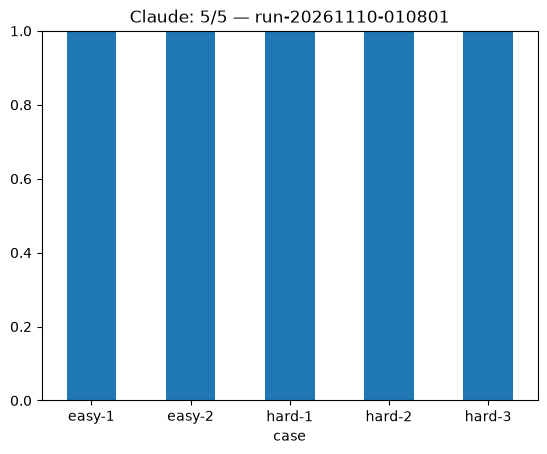

In [28]:
ax = df.set_index("case").score.plot.bar(ylim=(0, 1), rot=0,
    title=f"Claude: {df.score.count()}/{len(df)} — {df.attrs['session_id']}")
for position, value in enumerate(df.score):
    if pd.isna(value):
        ax.text(position, 0.04, "N/A", ha="center")
if df.score.notna().all():
    print(f"Средний балл: {df.score.mean():.2f}")


Что смотреть в Langfuse (http://localhost:3000): **Tracing → Sessions** — сессия `RUN_ID`, все прогоны рядом;
**Traces** — фильтр по тегу кейса, дерево agent → generation / tool, вход и выход каждого шага;
**Scores** — колонка `judge` у каждого трейса с комментарием судьи. При повторном запуске шаг 5 загружает готовые оценки по trace_id и вызывает судью только для трейсов без оценки.